# Scraping YouTube Comments
**Nama**: Asep Haryana Saputra
**Project**: Sentiment Analysis (YouTube Comments)

In [1]:
import pandas as pd
from youtube_comment_downloader import YoutubeCommentDownloader
import itertools
import os
import time

VIDEO_URLS = [
    'https://www.youtube.com/watch?v=k9a5LpSfp7c'
]

TARGET_TOTAL = 15000
OUTPUT_FILE = 'dataset_youtube.csv'

In [2]:
def scrape_multiple_videos(urls, target_total, output_file):
    downloader = YoutubeCommentDownloader()
    
    if os.path.exists(output_file):
        os.remove(output_file)
    
    pd.DataFrame(columns=['cid', 'text', 'time', 'author', 'votes', 'photo', 'heart']).to_csv(output_file, index=False)
    
    total_collected = 0
    per_video_limit = (target_total // len(urls)) + 500

    for url in urls:
        if total_collected >= target_total:
            break
            
        print(f"\nScraping {url}...")
        try:
            comments = downloader.get_comments_from_url(url, sort_by=1)
            
            video_count = 0
            batch_data = []
            
            for comment in itertools.islice(comments, per_video_limit):
                batch_data.append({
                    'cid': comment['cid'],
                    'text': comment['text'],
                    'time': comment['time'],
                    'author': comment['author'],
                    'votes': comment.get('votes', 0),
                    'photo': comment.get('photo', ''),
                    'heart': comment.get('heart', False)
                })
                video_count += 1
                total_collected += 1
                
                if video_count % 100 == 0:
                    # Append to CSV
                    df_batch = pd.DataFrame(batch_data)
                    df_batch.to_csv(output_file, mode='a', header=False, index=False)
                    batch_data = []
                    print(f"Video: {video_count} | Total: {total_collected}", end='\r')
            
            if batch_data:
                df_batch = pd.DataFrame(batch_data)
                df_batch.to_csv(output_file, mode='a', header=False, index=False)
                
            print(f"\nFinished video. Collected: {video_count}")
            
        except Exception as e:
            print(f"\nError scraping {url}: {e}")
            continue
            
    print(f"\nScraping complete. Total rows: {total_collected}")
    
scrape_multiple_videos(VIDEO_URLS, TARGET_TOTAL, OUTPUT_FILE)


Scraping https://www.youtube.com/watch?v=k9a5LpSfp7c...
Video: 15500 | Total: 15500
Finished video. Collected: 15500

Scraping complete. Total rows: 15500


In [3]:
if os.path.exists(OUTPUT_FILE):
    df = pd.read_csv(OUTPUT_FILE)
    print(f"Loaded {len(df)} rows from {OUTPUT_FILE}")
    print(df.head())

Loaded 15500 rows from dataset_youtube.csv
                          cid  \
0  UgwPwqqKva-HTdnXYTZ4AaABAg   
1  UgxR1u7olr8-eqRcFKF4AaABAg   
2  Ugy9oP4rkZ1mBBE8KZZ4AaABAg   
3  UgwiJeLZmh_Okzt5vA14AaABAg   
4  Ugy3C143yPQfO8gImBR4AaABAg   

                                                text               time  \
0  Apakah ada kejutan lagi dari mas lutfi halimawan?  5 tahun yang lalu   
1                           Mana y orangnya sekarang  4 bulan yang lalu   
2                        nama dia siapa sih gw lupa😅  9 bulan yang lalu   
3         nanti tonton ini ah, sambil main di ODIN4D  1 tahun yang lalu   
4                           Bang, ko ga upload lagii  1 tahun yang lalu   

             author  votes                                              photo  \
0   @RayBuatTrailer  10 rb  https://yt3.ggpht.com/ytc/AIdro_kLZbjoLKXjZu46...   
1   @SumaiyahGendut      0  https://yt3.ggpht.com/ec1JjokDrIS37438GFsv8IS0...   
2  @MamatAlkatiriii      0  https://yt3.ggpht.com/ytc/AIdro_kIQd

In [4]:
# Pastikan `df` ter-load: muat ulang dataset secara eksplisit jika belum ada
import pandas as pd
OUTPUT_FILE = 'dataset_youtube.csv'
if 'df' not in globals():
    df = pd.read_csv(OUTPUT_FILE)
    print(f"Loaded {len(df)} rows from {OUTPUT_FILE}")
else:
    print("Variabel df sudah ada, shape:", getattr(df, 'shape', None))

Variabel df sudah ada, shape: (15500, 7)


In [5]:
### Ringkasan Data (grafik lama dihapus)
# Sel ini hanya menampilkan ringkasan singkat dataset. Grafik lama yang kurang informatif telah dihapus
# untuk mengurangi kebingungan. Untuk visualisasi yang lebih baik jalankan sel "Perbaikan visualisasi"
# (sel berikutnya) yang menghasilkan histogram terpangkas, distribusi votes (log), timeline yang sudah
# menyaring outlier, dan menyimpan PNG ke folder `figures/`.

try:
    df
except NameError:
    raise RuntimeError("Variabel `df` tidak ditemukan. Jalankan sel yang memuat CSV (mis. `df = pd.read_csv(OUTPUT_FILE)`) terlebih dahulu.")

print('Bentuk dataset:', df.shape)
print('\nKolom:', df.columns.tolist())

# Tampilkan sample dan ringkasan singkat kolom penting (tanpa plotting)
display(df.head())

for col in ['text','votes','time','heart','label']:
    if col in df.columns:
        print(f"\nRingkasan kolom `{col}` (top 10 nilai):")
        display(df[col].astype(str).value_counts(dropna=False).head(10))

print('\nCatatan: jalankan sel "Perbaikan visualisasi" untuk grafik yang diperbaiki. File PNG disimpan di `figures/`.')


Bentuk dataset: (15500, 7)

Kolom: ['cid', 'text', 'time', 'author', 'votes', 'photo', 'heart']


,cid,text,time,author,votes,photo,heart
0,UgwPwqqKva-HTdnXYTZ4AaABAg,Apakah ada kejutan lagi dari mas lutfi halimawan?,5 tahun yang lalu,@RayBuatTrailer,10 rb,https://yt3.ggpht.com/ytc/AIdro_kLZbjoLKXjZu46...,False
1,UgxR1u7olr8-eqRcFKF4AaABAg,Mana y orangnya sekarang,4 bulan yang lalu,@SumaiyahGendut,0,https://yt3.ggpht.com/ec1JjokDrIS37438GFsv8IS0...,False
2,Ugy9oP4rkZ1mBBE8KZZ4AaABAg,nama dia siapa sih gw lupa😅,9 bulan yang lalu,@MamatAlkatiriii,0,https://yt3.ggpht.com/ytc/AIdro_kIQd925lZn3kNv...,False
3,UgwiJeLZmh_Okzt5vA14AaABAg,"nanti tonton ini ah, sambil main di ODIN4D",1 tahun yang lalu,@edtui-z5b,0,https://yt3.ggpht.com/ytc/AIdro_lXthx7ZWZqaCpA...,False
4,Ugy3C143yPQfO8gImBR4AaABAg,"Bang, ko ga upload lagii",1 tahun yang lalu,@ribel8944,0,https://yt3.ggpht.com/rIKvRuzBCrvSCPksL2GMM2ZC...,False



Ringkasan kolom `text` (top 10 nilai):


text
Anjay                                                                                                                                      552
Anjay trending                                                                                                                             126
Up                                                                                                                                         125
ANJAY                                                                                                                                      123
Anjayyy                                                                                                                                     73
Anjayy                                                                                                                                      61
anjay                                                                                                                                    


Ringkasan kolom `votes` (top 10 nilai):


votes
0    12460
1     1689
2      301
3      175
4       97
6       70
5       62
7       43
9       41
8       39
Name: count, dtype: int64


Ringkasan kolom `time` (top 10 nilai):


time
5 tahun yang lalu             14784
5 tahun yang lalu (diedit)      596
4 tahun yang lalu                81
3 tahun yang lalu                17
2 tahun yang lalu                 9
1 tahun yang lalu                 5
4 tahun yang lalu (diedit)        5
4 bulan yang lalu                 2
9 bulan yang lalu                 1
Name: count, dtype: int64


Ringkasan kolom `heart` (top 10 nilai):


heart
False    15483
True        17
Name: count, dtype: int64


Catatan: jalankan sel "Perbaikan visualisasi" untuk grafik yang diperbaiki. File PNG disimpan di `figures/`.


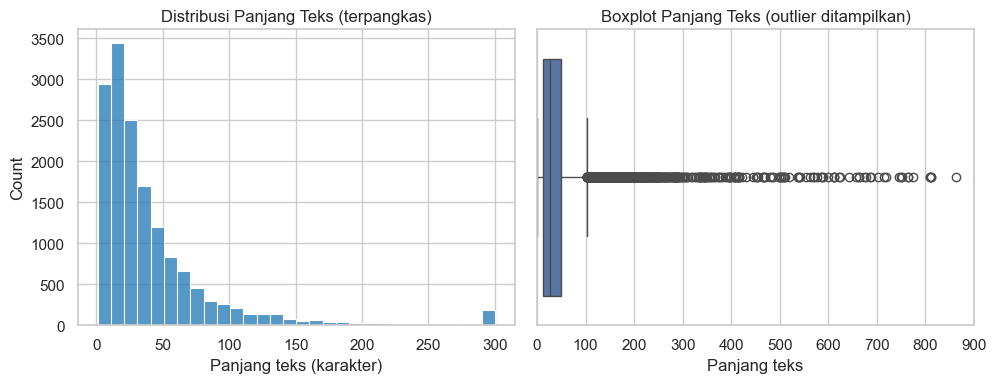

[SAVED] figures/text_length.png


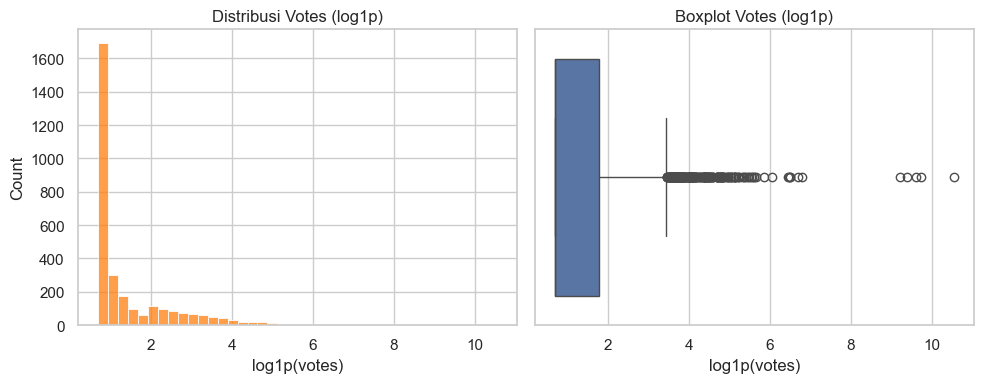

[SAVED] figures/votes_log.png

Ringkasan votes (numeric):
count    15500.000000
mean         7.957226
std        377.306080
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      38000.000000
Name: votes_num, dtype: float64
Percentiles: {0.5: 0.0, 0.75: 0.0, 0.9: 1.0, 0.99: 43.0}


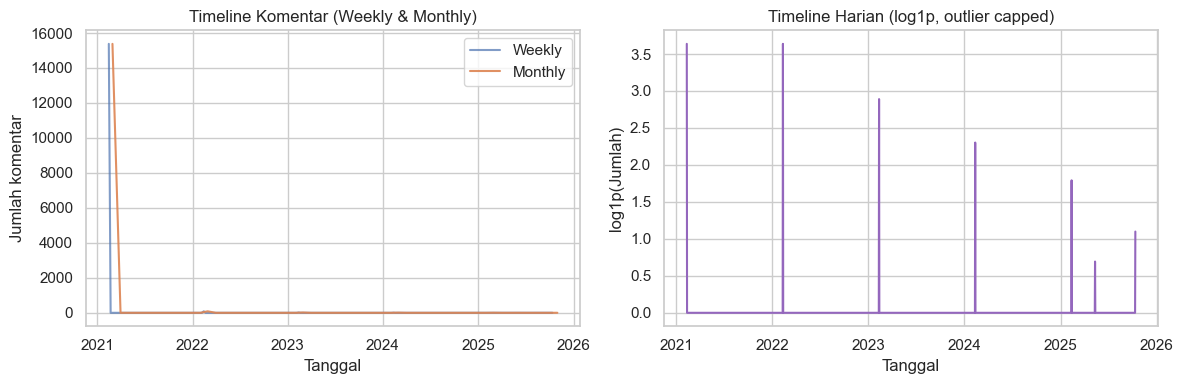

[SAVED] figures/timeline_comments.png

Top 3 hari dengan komentar terbanyak:
  - 2021-02-11: 15380 komentar
  - 2022-02-11: 86 komentar
  - 2023-02-11: 17 komentar


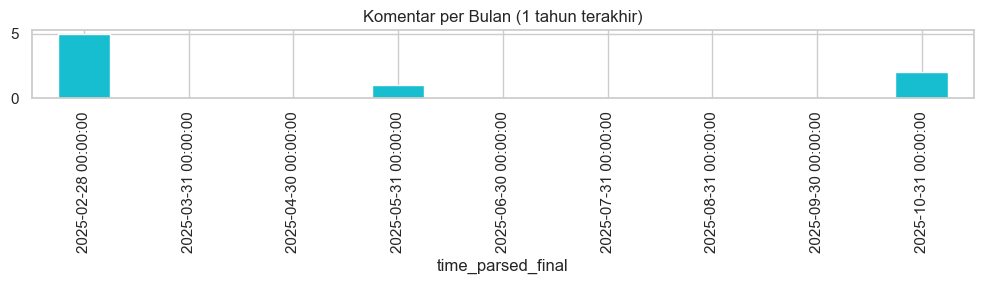

[SAVED] figures/timeline_recent.png


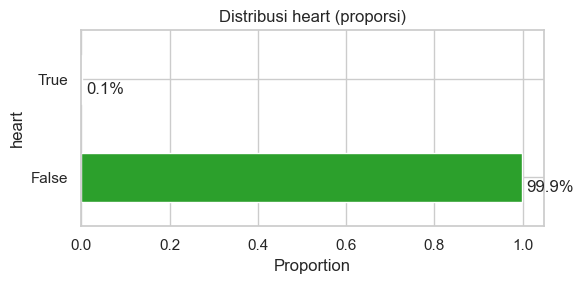

[SAVED] figures/dist_heart.png

Perbaikan visual selesai. Lihat folder `figures/` untuk PNG yang tersimpan.


In [6]:
# Perbaikan visualisasi: parsing waktu bahasa Indonesia, histogram terpangkas, dan histogram votes (log)
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import dateparser
from datetime import datetime

sns.set(style='whitegrid')
os.makedirs('figures', exist_ok=True)

# Pastikan df tersedia
if 'df' not in globals():
    raise RuntimeError('Variabel `df` tidak ditemukan. Jalankan sel yang memuat CSV terlebih dahulu.')

# Parsing waktu (heuristik untuk format relative bahasa Indonesia)
today = pd.Timestamp.now().normalize()

def parse_rel_time_id(s):
    s = str(s).lower().strip()
    if s in ['', 'nan', 'none']:
        return pd.NaT
    # common phrases
    if any(k in s for k in ['yang lalu', 'yanglalu', 'yang  lalu', 'lalu', 'sekarang', 'baru saja', 'baru']):
        m = re.search(r'(\d+)\s*(tahun|th|bulan|bln|minggu|ming|hari|jam|menit|min|detik|d)', s)
        if m:
            num = int(m.group(1))
            unit = m.group(2)
            if 'tahun' in unit or unit == 'th':
                return today - pd.DateOffset(years=num)
            if 'bulan' in unit or unit == 'bln':
                return today - pd.DateOffset(months=num)
            if 'minggu' in unit or 'ming' in unit:
                return today - pd.Timedelta(weeks=num)
            if 'hari' in unit or unit == 'd':
                return today - pd.Timedelta(days=num)
            if 'jam' in unit:
                return today - pd.Timedelta(hours=num)
            if 'menit' in unit or unit == 'min':
                return today - pd.Timedelta(minutes=num)
            if 'detik' in unit:
                return today - pd.Timedelta(seconds=num)
        # fallback for words without numbers: 'sekarang', 'baru saja'
        if any(k in s for k in ['sekarang','baru saja','baru']):
            return today
    # fallback to dateparser (may parse absolute dates)
    try:
        dt = dateparser.parse(s, settings={'PREFER_DATES_FROM': 'past', 'RELATIVE_BASE': today.to_pydatetime()}, languages=['id'])
        return pd.Timestamp(dt) if dt else pd.NaT
    except Exception:
        return pd.NaT

# Create/merge time_parsed_improved
if 'time_parsed' not in df.columns or df['time_parsed'].isna().sum() > (0.2 * len(df)):
    df['time_parsed_improved'] = df['time'].astype(str).apply(parse_rel_time_id)
    # prefer original parsed if available
    if 'time_parsed' in df.columns:
        df['time_parsed_final'] = df['time_parsed'].fillna(df['time_parsed_improved'])
    else:
        df['time_parsed_final'] = df['time_parsed_improved']
else:
    df['time_parsed_final'] = df['time_parsed']

# --- Plot 1: teks panjang ---
df['text_len'] = df['text'].astype(str).str.len()
# cap at 300 chars (most comments are short)
cap = min(300, int(df['text_len'].quantile(0.99)))
df['text_len_capped'] = df['text_len'].clip(upper=cap)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.histplot(df['text_len_capped'], bins=30, color='tab:blue')
plt.title('Distribusi Panjang Teks (terpangkas)')
plt.xlabel('Panjang teks (karakter)')

plt.subplot(1,2,2)
sns.boxplot(x=df['text_len'])
plt.xlim(0, cap*3)
plt.title('Boxplot Panjang Teks (outlier ditampilkan)')
plt.xlabel('Panjang teks')

plt.tight_layout()
plt.savefig('figures/text_length.png', bbox_inches='tight')
plt.show()
print('[SAVED] figures/text_length.png')

# --- Plot 2: votes numeric (gunakan log1p) ---
if 'votes_num' not in df.columns:
    # try to parse numeric votes similar to previous helper
    def clean_votes_simple(v):
        try:
            s = str(v).lower().replace('\u00a0','').replace(',','').strip()
            mult = 1
            if 'rb' in s: mult = 1000; s = s.replace('rb','')
            if 'k' in s and 'rb' not in s: mult = 1000; s = s.replace('k','')
            if 'm' in s: mult = 1_000_000; s = s.replace('m','')
            m = re.search(r'[\d.]+', s)
            return float(m.group())*mult if m else 0.0
        except:
            return 0.0
    df['votes_num'] = df.get('votes', 0).apply(clean_votes_simple)

votes = df['votes_num'].fillna(0).astype(float)
if (votes > 0).any():
    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    sns.histplot(np.log1p(votes[votes>0]), bins=40, color='tab:orange')
    plt.title('Distribusi Votes (log1p)')
    plt.xlabel('log1p(votes)')

    plt.subplot(1,2,2)
    sns.boxplot(x=np.log1p(votes[votes>0]))
    plt.title('Boxplot Votes (log1p)')
    plt.xlabel('log1p(votes)')

    plt.tight_layout()
    plt.savefig('figures/votes_log.png', bbox_inches='tight')
    plt.show()
    print('[SAVED] figures/votes_log.png')
else:
    print('Tidak ada votes > 0 untuk divisualisasikan')

# show numeric summary and percentiles
print('\nRingkasan votes (numeric):')
print(votes.describe())
print('Percentiles:', votes.quantile([0.5,0.75,0.9,0.99]).to_dict())

# --- Plot 3: Timeline ---
if df['time_parsed_final'].notna().sum() > 0:
    tmp = df.dropna(subset=['time_parsed_final']).set_index('time_parsed_final')
    # resample weekly and monthly (robust)
    weekly = tmp.resample('W').size()
    try:
        # 'ME' = month end frequency (pandas newer versions)
        monthly = tmp.resample('ME').size()
    except Exception:
        try:
            monthly = tmp.resample('MS').size()
        except Exception:
            # fallback: aggregate weekly to monthly periods
            monthly = weekly.groupby(weekly.index.to_period('M')).sum()
            monthly.index = monthly.index.to_timestamp()

    # Cap extreme daily spikes for visualization (but keep original counts for annotation)
    daily = tmp.resample('D').size()
    cap_val = max(1, int(daily.quantile(0.999)))
    daily_capped = daily.clip(upper=cap_val)

    plt.figure(figsize=(12,4))
    # left: linear weekly & monthly
    plt.subplot(1,2,1)
    plt.plot(weekly.index, weekly.values, label='Weekly', alpha=0.7)
    plt.plot(monthly.index, monthly.values, label='Monthly', alpha=0.9)
    plt.title('Timeline Komentar (Weekly & Monthly)')
    plt.xlabel('Tanggal')
    plt.ylabel('Jumlah komentar')
    plt.legend()

    # right: log view of daily (handles spikes)
    plt.subplot(1,2,2)
    plt.plot(daily_capped.index, np.log1p(daily_capped.values), color='tab:purple')
    plt.title('Timeline Harian (log1p, outlier capped)')
    plt.xlabel('Tanggal')
    plt.ylabel('log1p(Jumlah)')

    plt.tight_layout()
    plt.savefig('figures/timeline_comments.png', bbox_inches='tight')
    plt.show()
    print('[SAVED] figures/timeline_comments.png')

    # Annotasi puncak teratas (3 tanggal dengan jumlah terbesar)
    top_days = daily.nlargest(3)
    print('\nTop 3 hari dengan komentar terbanyak:')
    for dt, val in top_days.items():
        print(f"  - {pd.Timestamp(dt).date()}: {int(val)} komentar")

    # Zoom: jika ada puncak besar, zoom in ke rentang 1 tahun terakhir (monthly)
    last_year = pd.Timestamp.now() - pd.DateOffset(years=1)
    if (isinstance(monthly.index, pd.DatetimeIndex) and not monthly.empty and monthly.index.max() > last_year):
        recent = monthly[monthly.index > last_year]
        if recent.sum() > 0:
            plt.figure(figsize=(10,3))
            recent.plot(kind='bar', color='tab:cyan')
            plt.title('Komentar per Bulan (1 tahun terakhir)')
            plt.tight_layout()
            plt.savefig('figures/timeline_recent.png', bbox_inches='tight')
            plt.show()
            print('[SAVED] figures/timeline_recent.png')
else:
    print('Tidak ada data waktu yang valid untuk timeline.')

# --- Plot 4: Distribusi heart / labels ---
for col in ['heart','label']:
    if col in df.columns:
        plt.figure(figsize=(6,3))
        counts = df[col].value_counts(normalize=True).sort_index()
        ax = counts.plot(kind='barh', color='tab:green')
        plt.xlabel('Proportion')
        plt.title(f'Distribusi {col} (proporsi)')
        for p in ax.patches:
            ax.annotate(f"{p.get_width()*100:.1f}%", (p.get_width()+0.01, p.get_y()+0.1))
        plt.tight_layout()
        fname = f'figures/dist_{col}.png'
        plt.savefig(fname, bbox_inches='tight')
        plt.show()
        print(f'[SAVED] {fname}')

print('\nPerbaikan visual selesai. Lihat folder `figures/` untuk PNG yang tersimpan.')

Votes (numeric) sample:


,votes,votes_num
0,10 rb,10000.0
1,0,0.0
2,0,0.0
3,0,0.0
4,0,0.0


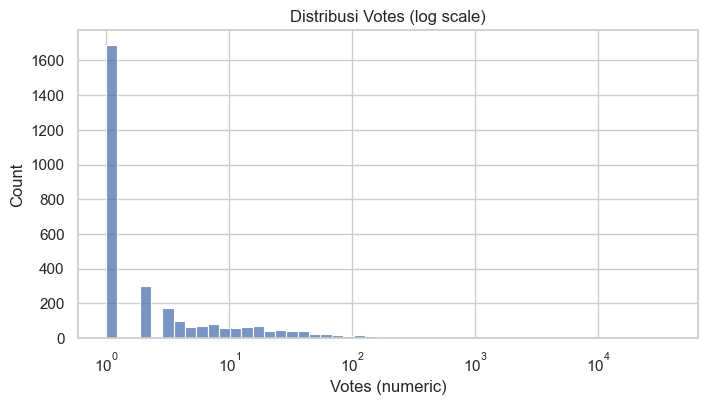

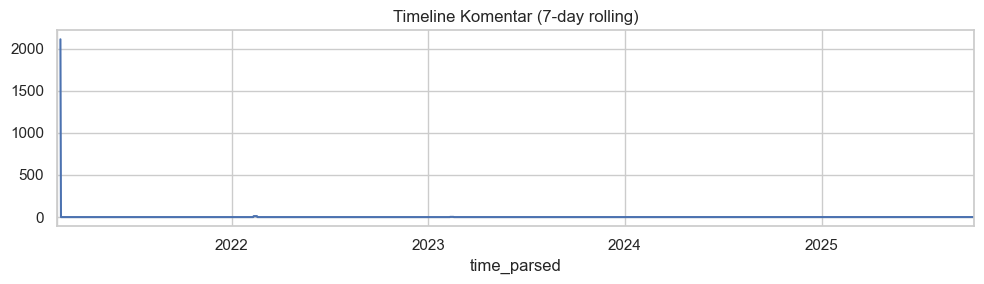

In [7]:
# Bersihkan kolom `votes` menjadi numeric dan parse kolom `time` menjadi datetime (menggunakan dateparser)
import dateparser
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid')

def clean_votes(v):
    if pd.isna(v): return 0.0
    s = str(v).lower().replace('\u00a0','').replace(',','').strip()
    mult = 1
    if 'rb' in s: mult = 1000; s = s.replace('rb','')
    if 'k' in s and 'rb' not in s: mult = 1000; s = s.replace('k','')
    if 'm' in s: mult = 1_000_000; s = s.replace('m','')
    m = re.search(r'[\d.]+', s)
    try:
        return float(m.group())*mult if m else 0.0
    except:
        return 0.0

# Terapkan
if 'df' in globals():
    df['votes_num'] = df['votes'].apply(clean_votes)
    df['time_parsed'] = df['time'].astype(str).apply(lambda x: dateparser.parse(x, settings={'PREFER_DATES_FROM': 'past'}))
    print('Votes (numeric) sample:')
    display(df[['votes','votes_num']].head())
else:
    raise RuntimeError('Variabel `df` tidak ditemukan. Jalankan sel yang memuat CSV terlebih dahulu.')

# Plot distribusi votes (log scale untuk ulasan)
plt.figure(figsize=(8,4))
if (df['votes_num'] > 0).any():
    sns.histplot(df[df['votes_num']>0]['votes_num'], bins=50, log_scale=(True,False))
    plt.title('Distribusi Votes (log scale)')
    plt.xlabel('Votes (numeric)')
    plt.show()
else:
    print('Tidak ada nilai votes > 0')

# Timeline jika ada data waktu parse
if df['time_parsed'].dropna().shape[0] > 0:
    counts = df.dropna(subset=['time_parsed']).set_index('time_parsed').resample('D').size()
    if counts.sum() > 0:
        plt.figure(figsize=(10,3))
        counts.rolling(window=7).mean().plot()
        plt.title('Timeline Komentar (7-day rolling)')
        plt.tight_layout()
        plt.show()
    else:
        print('Tidak ada data waktu yang cukup untuk timeline.')
else:
    print('Tidak ada waktu yang berhasil diparse.')